## Import Librarys

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## Load Dataset


In [2]:
df = pd.read_csv("Loan_approval_data.csv")

## Understand The Data


In [3]:
df.sample(10)
df.head()
df.info()
df.isnull().sum()
df.describe()
df.shape

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 20 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_ID        950 non-null    float64
 1   Applicant_Income    950 non-null    float64
 2   Coapplicant_Income  950 non-null    float64
 3   Employment_Status   950 non-null    str    
 4   Age                 950 non-null    float64
 5   Marital_Status      950 non-null    str    
 6   Dependents          950 non-null    float64
 7   Credit_Score        950 non-null    float64
 8   Existing_Loans      950 non-null    float64
 9   DTI_Ratio           950 non-null    float64
 10  Savings             950 non-null    float64
 11  Collateral_Value    950 non-null    float64
 12  Loan_Amount         950 non-null    float64
 13  Loan_Term           950 non-null    float64
 14  Loan_Purpose        950 non-null    str    
 15  Property_Area       950 non-null    str    
 16  Education_Level   

(1000, 20)

## Remove the Applicant_ID and missing output features rows.


In [4]:

df = df.drop('Applicant_ID', axis= 1)
df = df.dropna(subset=['Loan_Approved'])


## EDA - Exploratory Data Analysis


In [5]:
categorical_cols = df.select_dtypes(include="str").columns
numerical_cols = df.select_dtypes(include="number").columns

In [6]:
numerical_cols.size + categorical_cols.size

19

Text(0.5, 1.0, 'how many Loan approved or not?')

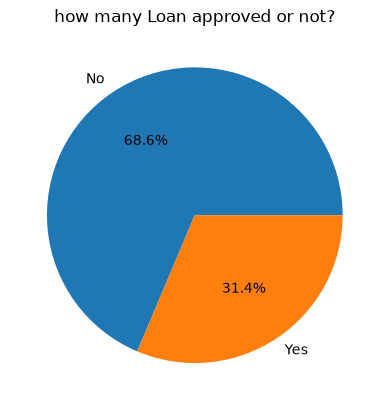

In [7]:
# how balanced our classes are?

# Analyze Categories

classes_count = df["Loan_Approved"].value_counts()

plt.pie(classes_count, labels=["No", "Yes"], autopct="%1.1f%%")
plt.title("how many Loan approved or not?")

[Text(0, 0, '567'), Text(0, 0, '335')]

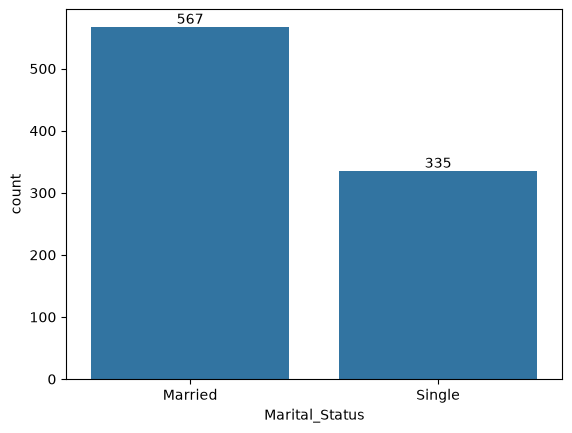

In [8]:
mar_sts_cnt = df["Marital_Status"].value_counts()

ax = sns.barplot(mar_sts_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '538'), Text(0, 0, '365')]

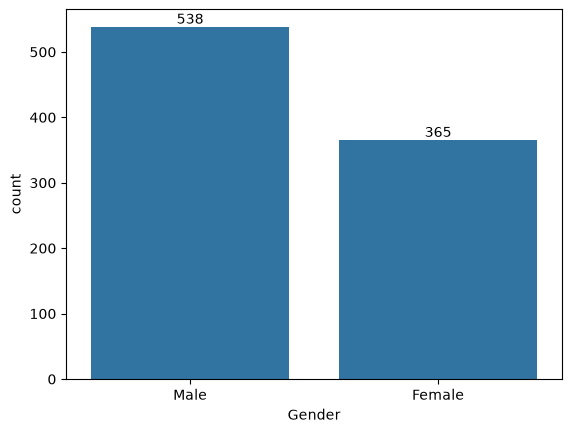

In [9]:
gen_cnt = df["Gender"].value_counts()

ax = sns.barplot(gen_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '638'), Text(0, 0, '265')]

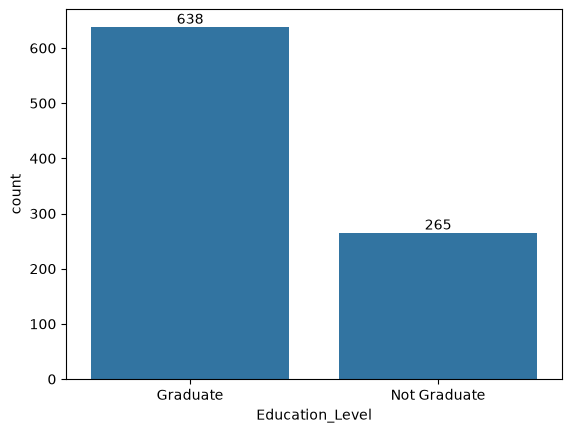

In [10]:
edu_cnt = df["Education_Level"].value_counts()

ax = sns.barplot(edu_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '448'), Text(0, 0, '199'), Text(0, 0, '173'), Text(0, 0, '86')]

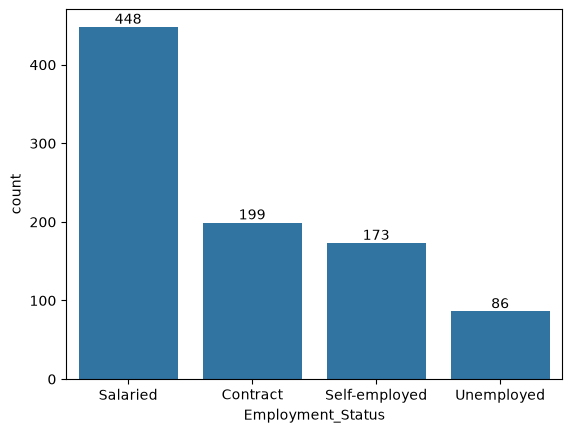

In [11]:
emp_sts_cnt = df["Employment_Status"].value_counts()

ax = sns.barplot(emp_sts_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '192'),
 Text(0, 0, '192'),
 Text(0, 0, '180'),
 Text(0, 0, '169'),
 Text(0, 0, '169')]

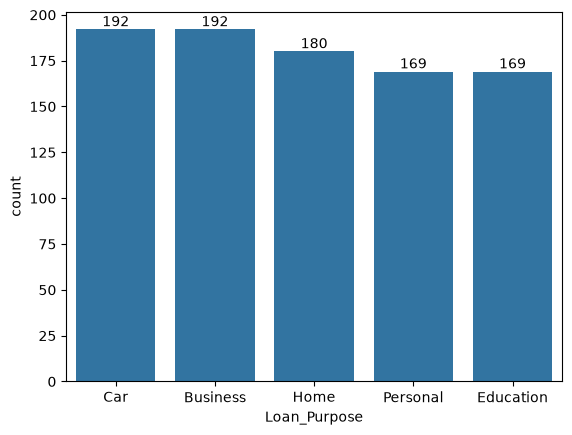

In [12]:
loan_pur_cnt = df["Loan_Purpose"].value_counts()

ax = sns.barplot(loan_pur_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '443'), Text(0, 0, '278'), Text(0, 0, '180')]

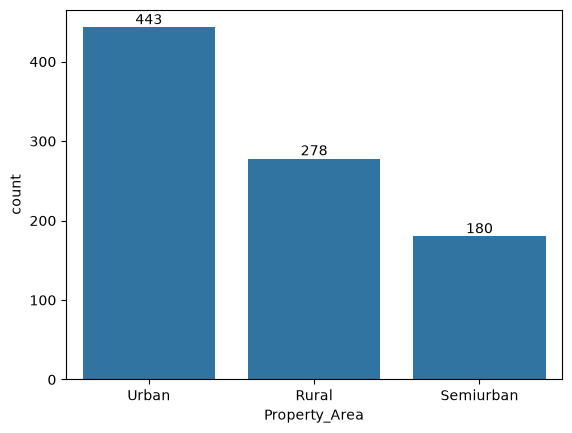

In [13]:
pro_ar_cnt = df["Property_Area"].value_counts()

ax = sns.barplot(pro_ar_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '351'),
 Text(0, 0, '191'),
 Text(0, 0, '136'),
 Text(0, 0, '130'),
 Text(0, 0, '95')]

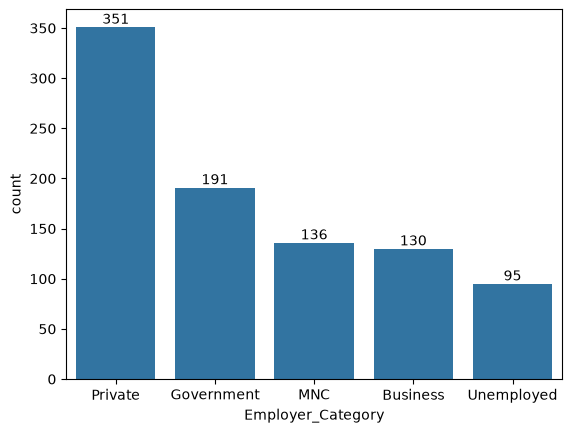

In [14]:
emp_cat_cnt = df["Employer_Category"].value_counts()

ax = sns.barplot(emp_cat_cnt)
ax.bar_label(ax.containers[0])

In [15]:
numerical_cols

Index(['Applicant_Income', 'Coapplicant_Income', 'Age', 'Dependents',
       'Credit_Score', 'Existing_Loans', 'DTI_Ratio', 'Savings',
       'Collateral_Value', 'Loan_Amount', 'Loan_Term'],
      dtype='str')

<Axes: xlabel='Applicant_Income', ylabel='Count'>

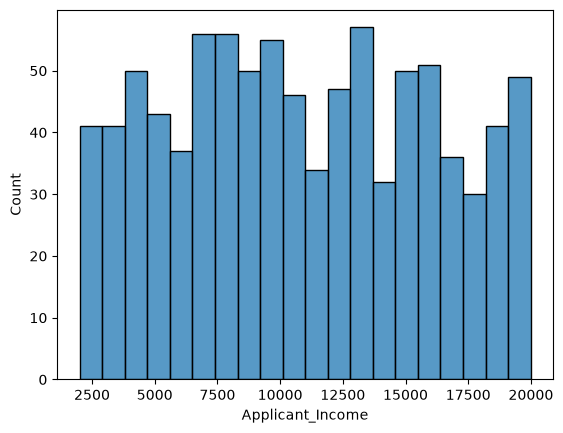

In [16]:
# analyze numerical

sns.histplot(
    data = df,
    x = "Applicant_Income",
    bins=20
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

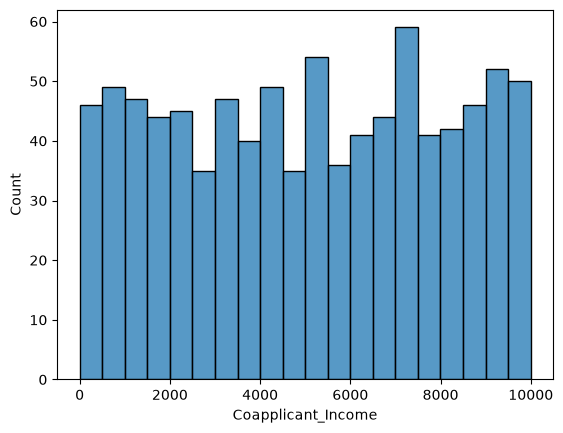

In [17]:
sns.histplot(
    data = df,
    x = "Coapplicant_Income",
    bins=20
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

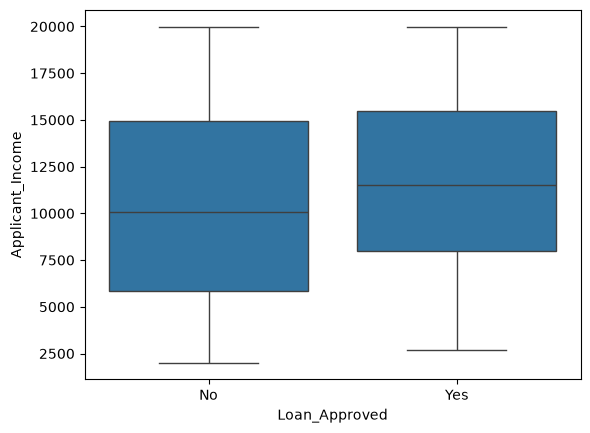

In [18]:
# outliers - box plots

sns.boxplot(
    data=df,
    x="Loan_Approved",
    y="Applicant_Income"
)

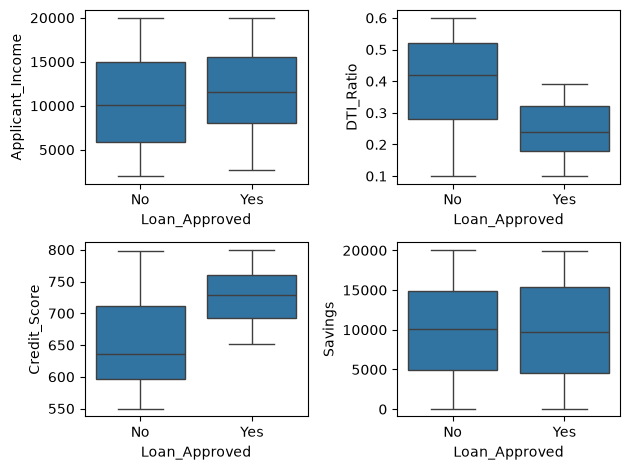

In [19]:
fig, axes = plt.subplots(2,2)

sns.boxplot(ax=axes[0,0], data=df, x="Loan_Approved", y="Applicant_Income"),
sns.boxplot(ax=axes[1,0], data=df, x="Loan_Approved", y="Credit_Score"),
sns.boxplot(ax=axes[0,1], data=df, x="Loan_Approved", y="DTI_Ratio"),
sns.boxplot(ax=axes[1,1], data=df, x="Loan_Approved", y="Savings")

plt.tight_layout()

<Axes: xlabel='Credit_Score', ylabel='Count'>

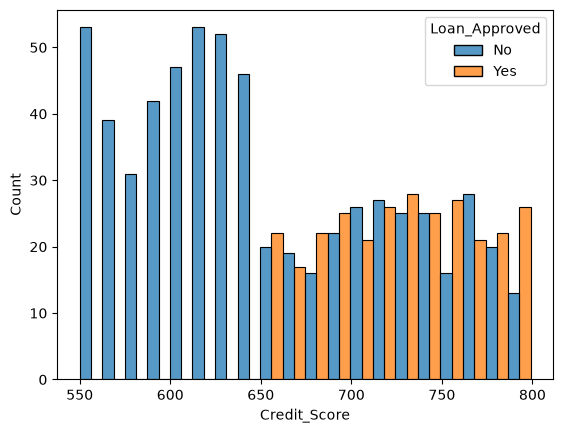

In [20]:
# what is the relation between Credit Score and Loan Approved.

sns.histplot(
    data=df,
    x='Credit_Score',
    hue='Loan_Approved',
    multiple="dodge",
    bins=20
)

<Axes: xlabel='Applicant_Income', ylabel='Count'>

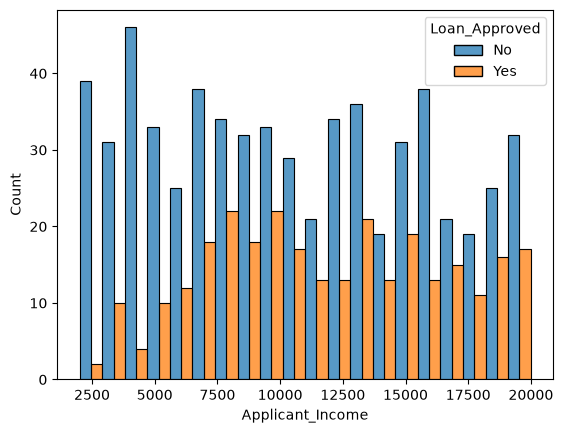

In [21]:
# what is the relation between Applicant_Income and Loan Approved.

sns.histplot(
    data=df,
    x='Applicant_Income',
    hue='Loan_Approved',
    multiple="dodge",
    bins=20
)

## Correlation Heatmap


<Axes: >

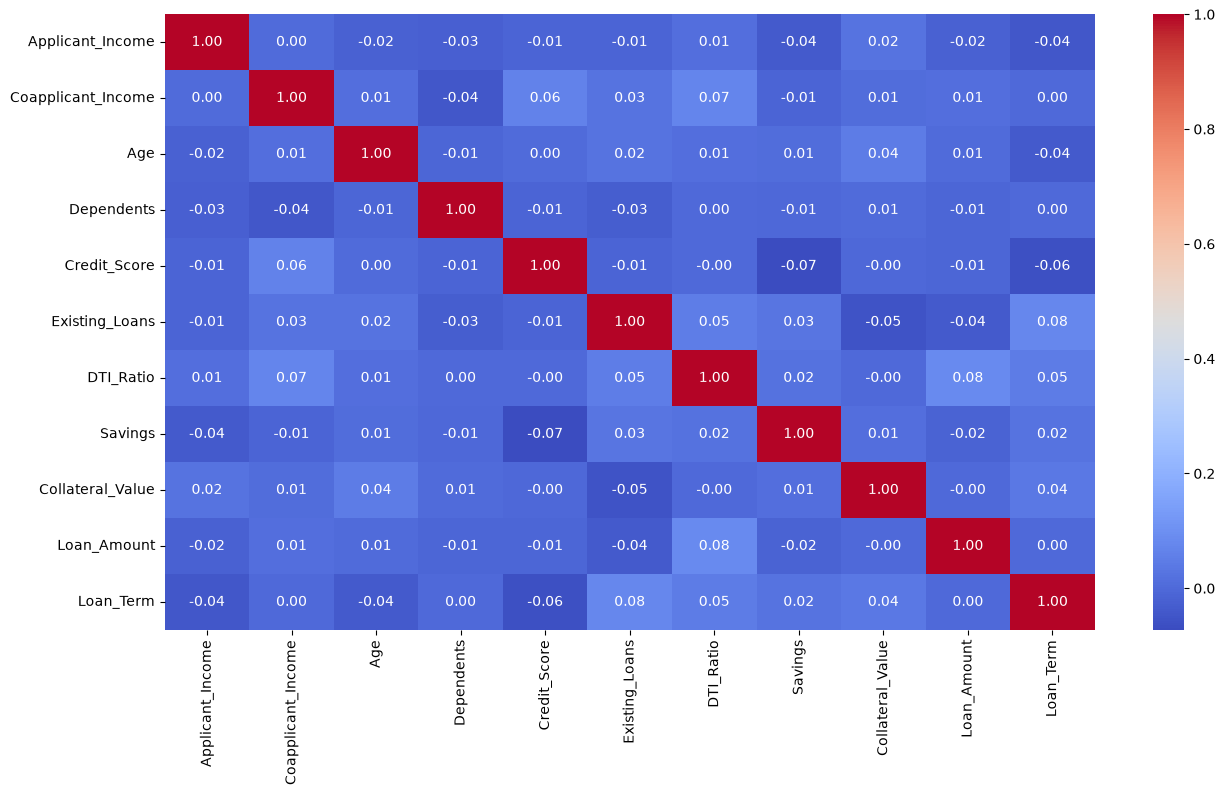

In [22]:
num_cols = df.select_dtypes(include="number")
corr_matrix = num_cols.corr()

plt.figure(figsize=(15, 8))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

## Separate features and target


In [23]:
X = df.drop(columns=['Loan_Approved'])
y = df['Loan_Approved'].map({'No': 0, 'Yes': 1})

## Train-Test-Split 


In [24]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [25]:
print("Y Train Distribution:")
print(y_train.value_counts())

print("\nY Test Distribution:")
print(y_test.value_counts())

print("\nMissing values:")
print(y_train.isnull().sum())
print(y_test.isnull().sum())

Y Train Distribution:
Loan_Approved
0    522
1    238
Name: count, dtype: int64

Y Test Distribution:
Loan_Approved
0    130
1     60
Name: count, dtype: int64

Missing values:
0
0


In [26]:
print(y_train.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)

Loan_Approved
0    68.684211
1    31.315789
Name: proportion, dtype: float64
Loan_Approved
0    68.421053
1    31.578947
Name: proportion, dtype: float64


## Pipeline - Handel_missing_value & Feature Encoding

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

num_cols = [
    'Applicant_Income',
    'Coapplicant_Income',
    'Age',
    'Dependents',
    'Credit_Score',
    'Existing_Loans',
    'DTI_Ratio',
    'Savings',
    'Collateral_Value',
    'Loan_Amount',
    'Loan_Term'
]

ohe_cols = [
    'Employment_Status',
    'Marital_Status',
    'Loan_Purpose',
    'Property_Area',
    'Gender',
    'Employer_Category'
]

ordinal_cols = ['Education_Level']

# Numerical pipeline
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

# One-hot encoding pipeline
ohe_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        drop='first',
        sparse_output=False,
        handle_unknown='ignore'
    ))
])

# Ordinal encoding pipeline
ordinal_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(
        categories=[['Not Graduate', 'Graduate']]
    ))
])


## ColumnTransformer

In [28]:
from sklearn.compose import ColumnTransformer

transformer = ColumnTransformer([
    ('num', num_pipeline, num_cols),
    ('ohe', ohe_pipeline, ohe_cols),
    ('ordinal', ordinal_pipeline, ordinal_cols)
])


## Fit and transform

In [29]:
X_train_transformed = transformer.fit_transform(X_train)

X_test_transformed = transformer.transform(X_test)

## Feature Scaling

In [30]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_transformed_scaled = scaler.fit_transform(X_train_transformed)

X_test_transformed_scaled = scaler.transform(X_test_transformed)

## Train & Evaluate Models

In [31]:
# Logistic regression

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train_transformed_scaled, y_train)

y_pred = log_model.predict(X_test_transformed_scaled)

# Evaluation
print("Logistic Regression Model")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Logistic Regression Model
Precision:  0.8545454545454545
Recall:  0.7833333333333333
F1 score:  0.8173913043478261
Accuracy:  0.8894736842105263
CM:  [[122   8]
 [ 13  47]]


In [32]:
# KNN

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_transformed_scaled, y_train)

y_pred = knn_model.predict(X_test_transformed_scaled)

# Evaluation
print("KNN Model")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

KNN Model
Precision:  0.5918367346938775
Recall:  0.48333333333333334
F1 score:  0.5321100917431193
Accuracy:  0.7315789473684211
CM:  [[110  20]
 [ 31  29]]


In [33]:
# Naive Bayes

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()
nb_model.fit(X_train_transformed_scaled, y_train)

y_pred = nb_model.predict(X_test_transformed_scaled)

# Evaluation
print("Naive Bayes Model")
print("Precision: ", precision_score(y_test, y_pred))
print("Recall: ", recall_score(y_test, y_pred))
print("F1 score: ", f1_score(y_test, y_pred))
print("Accuracy: ", accuracy_score(y_test, y_pred))
print("CM: ", confusion_matrix(y_test, y_pred))

Naive Bayes Model
Precision:  0.86
Recall:  0.7166666666666667
F1 score:  0.7818181818181819
Accuracy:  0.8736842105263158
CM:  [[123   7]
 [ 17  43]]


## Evaluation metrics

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

# Accuracy
print("Accuracy:", accuracy_score(y_test, y_pred))

# Precision
print("Precision:", precision_score(y_test, y_pred))

# Recall
print("Recall:", recall_score(y_test, y_pred))

# F1 Score
print("F1 Score:", f1_score(y_test, y_pred))

# ROC-AUC
y_prob = log_model.predict_proba(X_test_transformed_scaled)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

# Classification Report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Not Approved', 'Approved']
))

Accuracy: 0.8736842105263158
Precision: 0.86
Recall: 0.7166666666666667
F1 Score: 0.7818181818181819
ROC-AUC: 0.9197435897435897

Classification Report:
              precision    recall  f1-score   support

Not Approved       0.88      0.95      0.91       130
    Approved       0.86      0.72      0.78        60

    accuracy                           0.87       190
   macro avg       0.87      0.83      0.85       190
weighted avg       0.87      0.87      0.87       190



## Confusion Matrix

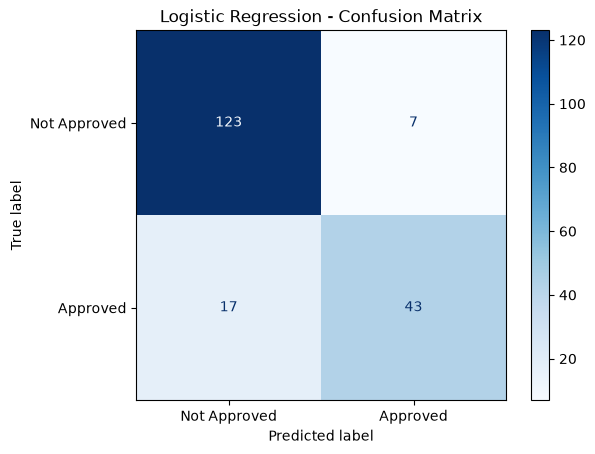

In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Approved', 'Approved']
)

disp.plot(cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix')
plt.show()

## ROC-AUC

In [36]:
from sklearn.metrics import roc_auc_score

models = {
    'Logistic Regression': log_model,
    'KNN': knn_model,
    'Naive Bayes': nb_model
}

for name, model in models.items():

    y_prob = model.predict_proba(
        X_test_transformed_scaled
    )[:, 1]

    print(name, roc_auc_score(y_test, y_prob))

Logistic Regression 0.9197435897435897
KNN 0.7828205128205128
Naive Bayes 0.9416666666666667


## Multiple Evaluation metrics

In [37]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score, roc_auc_score
)

models = {
    'Logistic Regression': log_model,
    'KNN': knn_model,
    'Naive Bayes': nb_model
}

for name, model in models.items():

    y_pred = model.predict(X_test_transformed_scaled)
    y_prob = model.predict_proba(X_test_transformed_scaled)[:, 1]

    print(f'\n{name}')
    print('Accuracy:', accuracy_score(y_test, y_pred))
    print('Precision:', precision_score(y_test, y_pred))
    print('Recall:', recall_score(y_test, y_pred))
    print('F1:', f1_score(y_test, y_pred))
    print('ROC-AUC:', roc_auc_score(y_test, y_prob))


Logistic Regression
Accuracy: 0.8894736842105263
Precision: 0.8545454545454545
Recall: 0.7833333333333333
F1: 0.8173913043478261
ROC-AUC: 0.9197435897435897

KNN
Accuracy: 0.7315789473684211
Precision: 0.5918367346938775
Recall: 0.48333333333333334
F1: 0.5321100917431193
ROC-AUC: 0.7828205128205128

Naive Bayes
Accuracy: 0.8736842105263158
Precision: 0.86
Recall: 0.7166666666666667
F1: 0.7818181818181819
ROC-AUC: 0.9416666666666667


## Decision tree 

In [38]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(random_state=42)

# Training
dt_model.fit(X_train_transformed, y_train)

# Prediction
y_pred_dt = dt_model.predict(X_test_transformed)

## evaluation

In [39]:
y_prob_dt = dt_model.predict_proba(X_test_transformed)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

Accuracy: 0.9473684210526315
Precision: 0.9166666666666666
Recall: 0.9166666666666666
F1: 0.9166666666666666
ROC-AUC: 0.9391025641025641


## important check: Overfitting

In [40]:
print("Training Accuracy:",
      dt_model.score(X_train_transformed, y_train))

print("Testing Accuracy:",
      dt_model.score(X_test_transformed, y_test))

Training Accuracy: 1.0
Testing Accuracy: 0.9473684210526315


## Random Forest

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Training
rf_model.fit(X_train_transformed, y_train)

# Prediction
y_pred_rf = rf_model.predict(X_test_transformed)

# Probability
y_prob_rf = rf_model.predict_proba(
    X_test_transformed
)[:, 1]

## Evaluation

In [42]:
print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

Accuracy: 0.9421052631578948
Precision: 0.9152542372881356
Recall: 0.9
F1: 0.907563025210084
ROC-AUC: 0.9816666666666667


## important check: Overfitting

In [43]:
print("Random Forest Training Accuracy:",
      rf_model.score(X_train_transformed, y_train))

print("Random Forest Testing Accuracy:",
      rf_model.score(X_test_transformed, y_test))

Random Forest Training Accuracy: 1.0
Random Forest Testing Accuracy: 0.9421052631578948


## 5-Fold Cross Validation

In [44]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42
    )
}

scoring = [
    'accuracy',
    'precision',
    'recall',
    'f1',
    'roc_auc'
]

for name, model in models.items():

    pipe = Pipeline([
        ('preprocessor', transformer),
        ('model', model)
    ])

    scores = cross_validate(
        pipe,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True
    )

    print(f'\n{name}')
    print('Training Accuracy:',
          scores['train_accuracy'].mean())
    print('CV Accuracy:',
          scores['test_accuracy'].mean())
    print('CV F1:',
          scores['test_f1'].mean())
    print('CV ROC-AUC:',
          scores['test_roc_auc'].mean())


Decision Tree
Training Accuracy: 1.0
CV Accuracy: 0.9328947368421053
CV F1: 0.8924472973213176
CV ROC-AUC: 0.9213102057516952

Random Forest
Training Accuracy: 1.0
CV Accuracy: 0.95
CV F1: 0.9195437613098786
CV ROC-AUC: 0.9829442366144494


## Hyperparameter Tuning

In [47]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier


# pipeline

rf_pipeline = Pipeline([
    ('preprocessor', transformer),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=1
    ))
])



# Hyperparameter search space

param_grid = {
    'model__n_estimators': [100, 200, 300, 500],

    'model__max_depth': [None, 5, 8, 10, 12, 15, 20, 25],

    'model__min_samples_split': [2, 5, 10, 15, 20],

    'model__min_samples_leaf': [1, 2, 4, 6, 8],

    'model__max_features': ['sqrt', 'log2', None],

    'model__class_weight': [None, 'balanced']
}



# RandomizedSearchCV

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=param_grid,
    n_iter=40,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)


# Training

random_search.fit(X_train, y_train)


# Best parameters

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest CV ROC-AUC:")
print(random_search.best_score_)


# Top 5 combinations

results = pd.DataFrame(random_search.cv_results_)

results = results.sort_values('rank_test_score')

results[
    ['params', 'mean_train_score',
     'mean_test_score', 'std_test_score']
].head(5)

Fitting 5 folds for each of 40 candidates, totalling 200 fits
Best Parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 8, 'model__max_features': None, 'model__max_depth': 10, 'model__class_weight': None}

Best CV ROC-AUC:
0.984832899812953


,params,mean_train_score,mean_test_score,std_test_score
13,"{'model__n_estimators': 100, 'model__min_sampl...",0.997829,0.984833,0.006562
11,"{'model__n_estimators': 500, 'model__min_sampl...",0.997801,0.984790,0.006390
0,"{'model__n_estimators': 100, 'model__min_sampl...",0.998722,0.984749,0.006489
39,"{'model__n_estimators': 500, 'model__min_sampl...",0.998778,0.984667,0.006349
34,"{'model__n_estimators': 300, 'model__min_sampl...",0.998116,0.984387,0.006724


## Final tuned model evaluate

In [48]:
best_rf_model = random_search.best_estimator_

y_pred_tuned = best_rf_model.predict(X_test)

y_prob_tuned = best_rf_model.predict_proba(X_test)[:, 1]

## Evaluation

In [49]:
print("Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

print("Precision:",
      precision_score(y_test, y_pred_tuned))

print("Recall:",
      recall_score(y_test, y_pred_tuned))

print("F1 Score:",
      f1_score(y_test, y_pred_tuned))

print("ROC-AUC:",
      roc_auc_score(y_test, y_prob_tuned))

Accuracy: 0.9578947368421052
Precision: 0.8939393939393939
Recall: 0.9833333333333333
F1 Score: 0.9365079365079365
ROC-AUC: 0.9820512820512821


## Feature Importance

In [50]:
best_rf = random_search.best_estimator_

rf = best_rf.named_steps['model']

feature_names = best_rf.named_steps[
    'preprocessor'
].get_feature_names_out()

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
})

importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

print(importance_df.head(15))

                            Feature  Importance
6                    num__DTI_Ratio    0.429139
4                 num__Credit_Score    0.372766
0             num__Applicant_Income    0.125463
9                  num__Loan_Amount    0.050523
7                      num__Savings    0.006613
2                          num__Age    0.004815
1           num__Coapplicant_Income    0.004223
8             num__Collateral_Value    0.001673
10                   num__Loan_Term    0.001147
3                   num__Dependents    0.001104
21                 ohe__Gender_Male    0.000686
5               num__Existing_Loans    0.000421
14       ohe__Marital_Status_Single    0.000282
26         ordinal__Education_Level    0.000281
11  ohe__Employment_Status_Salaried    0.000269


## Visualization:

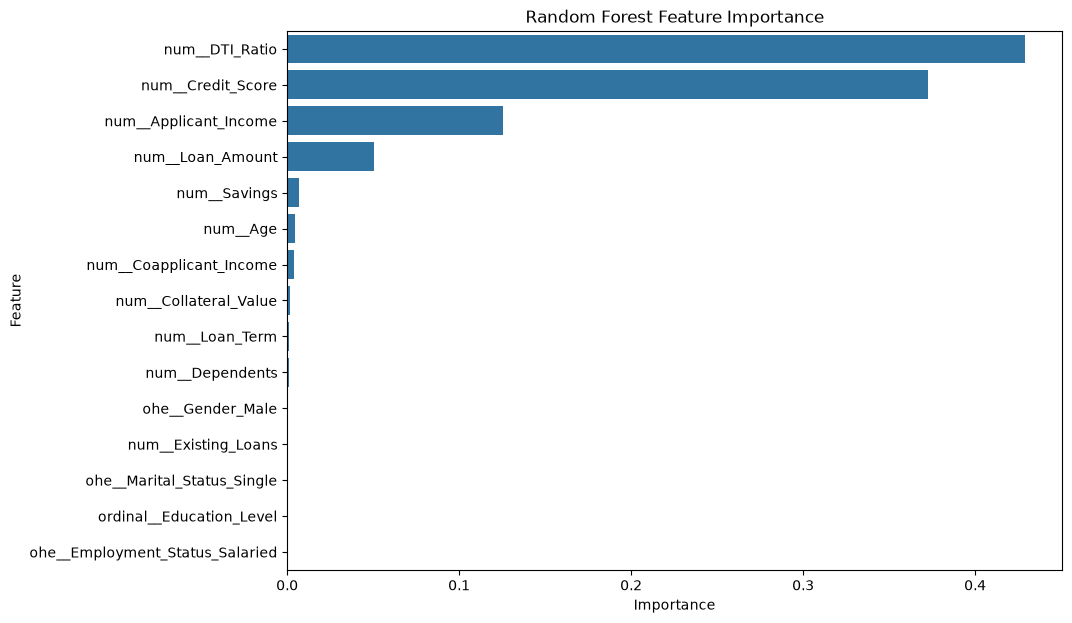

In [51]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature'
)

plt.title('Random Forest Feature Importance')
plt.show()

## Permutation Importance

In [52]:
from sklearn.inspection import permutation_importance

best_rf = random_search.best_estimator_

perm = permutation_importance(
    best_rf,
    X_test,
    y_test,
    n_repeats=20,
    random_state=42,
    scoring='roc_auc',
    n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': perm.importances_mean,
    'Std': perm.importances_std
}).sort_values(
    by='Importance',
    ascending=False
)

print(perm_df)

               Feature    Importance       Std
8            DTI_Ratio  2.934038e-01  0.026362
6         Credit_Score  2.853910e-01  0.042183
0     Applicant_Income  2.466667e-02  0.007142
11         Loan_Amount  9.416667e-03  0.003665
15     Education_Level  4.294872e-04  0.000158
16              Gender  3.269231e-04  0.000302
13        Loan_Purpose  2.371795e-04  0.000410
17   Employer_Category  4.487179e-05  0.000061
2    Employment_Status  2.775558e-17  0.000091
4       Marital_Status -5.128205e-05  0.000110
14       Property_Area -1.282051e-04  0.000091
10    Collateral_Value -1.410256e-04  0.000360
7       Existing_Loans -3.269231e-04  0.000125
9              Savings -4.294872e-04  0.002189
12           Loan_Term -5.256410e-04  0.000411
3                  Age -8.397436e-04  0.001668
5           Dependents -9.102564e-04  0.000645
1   Coapplicant_Income -9.679487e-04  0.001090


## Final Model Evaluation & Fairness Analysis.

## Gender-wise evaluation

In [53]:
from sklearn.metrics import accuracy_score, precision_score, recall_score
import pandas as pd

y_pred_tuned = best_rf_model.predict(X_test)

audit_df = pd.DataFrame({
    'Gender': X_test['Gender'].values,
    'Actual': y_test.values,
    'Predicted': y_pred_tuned
})

results = []

for gender, group in audit_df.groupby('Gender'):

    results.append({
        'Gender': gender,
        'Samples': len(group),
        'Approval Rate': group['Predicted'].mean(),
        'Accuracy': accuracy_score(group['Actual'], group['Predicted']),
        'Precision': precision_score(
            group['Actual'], group['Predicted'], zero_division=0
        ),
        'Recall': recall_score(
            group['Actual'], group['Predicted'], zero_division=0
        )
    })

gender_results = pd.DataFrame(results)

print(gender_results)

   Gender  Samples  Approval Rate  Accuracy  Precision    Recall
0  Female       71       0.366197  0.957746   0.884615  1.000000
1    Male      110       0.336364  0.954545   0.891892  0.970588


In [54]:
audit_df = pd.DataFrame({
    'Gender': X_test['Gender'].fillna('Unknown').values,
    'Actual': y_test.values,
    'Predicted': y_pred_tuned
})

print(audit_df.groupby('Gender').size())

Gender
Female      71
Male       110
Unknown      9
dtype: int64


## Fairness metrics

In [55]:
from sklearn.metrics import confusion_matrix
import numpy as np

for gender, group in audit_df.groupby('Gender'):

    tn, fp, fn, tp = confusion_matrix(
        group['Actual'],
        group['Predicted'],
        labels=[0, 1]
    ).ravel()

    fpr = fp / (fp + tn) if (fp + tn) else np.nan
    fnr = fn / (fn + tp) if (fn + tp) else np.nan

    print(f"\n{gender}")
    print("Samples:", len(group))
    print("FPR:", fpr)
    print("FNR:", fnr)
    print("Recall / TPR:", 1 - fnr if not np.isnan(fnr) else np.nan)


Female
Samples: 71
FPR: 0.0625
FNR: 0.0
Recall / TPR: 1.0

Male
Samples: 110
FPR: 0.05263157894736842
FNR: 0.029411764705882353
Recall / TPR: 0.9705882352941176

Unknown
Samples: 9
FPR: 0.0
FNR: 0.0
Recall / TPR: 1.0


## Model Saving

In [56]:
import joblib

joblib.dump(
    best_rf_model,
    'loan_approval_model.pkl'
)

['loan_approval_model.pkl']

## Model load

In [57]:
loaded_model = joblib.load('loan_approval_model.pkl')

## Model save

In [58]:
import joblib

best_rf_model = random_search.best_estimator_

joblib.dump(best_rf_model, 'loan_approval_model.pkl')

['loan_approval_model.pkl']

## New applicant test data 

In [59]:
new_applicant = pd.DataFrame([{
    'Applicant_Income': 15000,
    'Coapplicant_Income': 5000,
    'Employment_Status': 'Salaried',
    'Age': 35,
    'Marital_Status': 'Married',
    'Dependents': 1,
    'Credit_Score': 750,
    'Existing_Loans': 1,
    'DTI_Ratio': 0.25,
    'Savings': 12000,
    'Collateral_Value': 25000,
    'Loan_Amount': 15000,
    'Loan_Term': 36,
    'Loan_Purpose': 'Home',
    'Property_Area': 'Urban',
    'Education_Level': 'Graduate',
    'Gender': 'Male',
    'Employer_Category': 'MNC'
}])

## Prediction

In [60]:
# Load model
loaded_model = joblib.load('loan_approval_model.pkl')

# Prediction
prediction = loaded_model.predict(new_applicant)

# Approval probability
probability = loaded_model.predict_proba(new_applicant)[0][1]

if prediction[0] == 1:
    print("Loan Approved")
else:
    print("Loan Not Approved")

print("Approval Probability:", probability * 100, "%")

Loan Approved
Approval Probability: 100.0 %


# Scenario Testing

## Create applicants

In [61]:
import pandas as pd
import numpy as np

new_applicants = pd.DataFrame([
    {
        'Applicant_Income': 18000,
        'Coapplicant_Income': 5000,
        'Employment_Status': 'Salaried',
        'Age': 35,
        'Marital_Status': 'Married',
        'Dependents': 1,
        'Credit_Score': 790,
        'Existing_Loans': 0,
        'DTI_Ratio': 0.12,
        'Savings': 18000,
        'Collateral_Value': 40000,
        'Loan_Amount': 8000,
        'Loan_Term': 36,
        'Loan_Purpose': 'Home',
        'Property_Area': 'Urban',
        'Education_Level': 'Graduate',
        'Gender': 'Male',
        'Employer_Category': 'MNC'
    },
    {
        'Applicant_Income': 4000,
        'Coapplicant_Income': 500,
        'Employment_Status': 'Unemployed',
        'Age': 42,
        'Marital_Status': 'Single',
        'Dependents': 3,
        'Credit_Score': 560,
        'Existing_Loans': 4,
        'DTI_Ratio': 0.58,
        'Savings': 500,
        'Collateral_Value': 1000,
        'Loan_Amount': 38000,
        'Loan_Term': 84,
        'Loan_Purpose': 'Personal',
        'Property_Area': 'Rural',
        'Education_Level': 'Not Graduate',
        'Gender': 'Male',
        'Employer_Category': 'Unemployed'
    },
    {
        'Applicant_Income': 11000,
        'Coapplicant_Income': 5000,
        'Employment_Status': 'Salaried',
        'Age': 40,
        'Marital_Status': 'Married',
        'Dependents': 1,
        'Credit_Score': 675,
        'Existing_Loans': 2,
        'DTI_Ratio': 0.35,
        'Savings': 10000,
        'Collateral_Value': 25000,
        'Loan_Amount': 21000,
        'Loan_Term': 48,
        'Loan_Purpose': 'Home',
        'Property_Area': 'Semiurban',
        'Education_Level': 'Graduate',
        'Gender': 'Male',
        'Employer_Category': 'Private'
    }
])

new_applicants.index = [
    'Low Risk',
    'High Risk',
    'Borderline'
]

## Predictions

In [62]:
# Load saved pipeline
loaded_model = joblib.load('loan_approval_model.pkl')

# Predictions
predictions = loaded_model.predict(new_applicants)

probabilities = loaded_model.predict_proba(
    new_applicants
)[:, 1]

# Results
results = pd.DataFrame({
    'Applicant': new_applicants.index,
    'Prediction': np.where(
        predictions == 1,
        'Approved',
        'Not Approved'
    ),
    'Approval_Probability': np.round(
        probabilities * 100, 2
    )
})

print(results)

    Applicant    Prediction  Approval_Probability
0    Low Risk      Approved                 99.03
1   High Risk  Not Approved                  0.25
2  Borderline      Approved                 98.72


## Dataset-level verification

In [63]:
key_features = [
    'DTI_Ratio',
    'Credit_Score',
    'Applicant_Income',
    'Loan_Amount'
]

print(
    df.groupby('Loan_Approved')[key_features]
      .median()
      .T
)

Loan_Approved           No       Yes
DTI_Ratio             0.42      0.24
Credit_Score        636.00    728.50
Applicant_Income  10051.50  11530.00
Loan_Amount       22804.00  18143.50


# Final Confusion Matrix

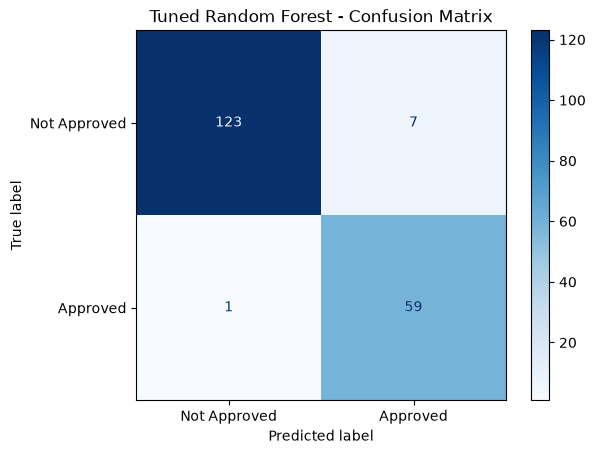

In [64]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred_tuned)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Not Approved', 'Approved']
)

disp.plot(cmap='Blues')
plt.title('Tuned Random Forest - Confusion Matrix')
plt.show()

## Classification Report

In [65]:
from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred_tuned,
    target_names=['Not Approved', 'Approved']
))

              precision    recall  f1-score   support

Not Approved       0.99      0.95      0.97       130
    Approved       0.89      0.98      0.94        60

    accuracy                           0.96       190
   macro avg       0.94      0.96      0.95       190
weighted avg       0.96      0.96      0.96       190



In [66]:
categorical_cols = [
    'Employment_Status',
    'Marital_Status',
    'Education_Level',
    'Gender',
    'Employer_Category',
    'Loan_Purpose',
    'Property_Area'
]

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].dropna().unique())


Employment_Status:
<ArrowStringArray>
['Salaried', 'Self-employed', 'Contract', 'Unemployed']
Length: 4, dtype: str

Marital_Status:
<ArrowStringArray>
['Married', 'Single']
Length: 2, dtype: str

Education_Level:
<ArrowStringArray>
['Not Graduate', 'Graduate']
Length: 2, dtype: str

Gender:
<ArrowStringArray>
['Female', 'Male']
Length: 2, dtype: str

Employer_Category:
<ArrowStringArray>
['Private', 'Government', 'Unemployed', 'MNC', 'Business']
Length: 5, dtype: str

Loan_Purpose:
<ArrowStringArray>
['Personal', 'Car', 'Business', 'Home', 'Education']
Length: 5, dtype: str

Property_Area:
<ArrowStringArray>
['Urban', 'Semiurban', 'Rural']
Length: 3, dtype: str


In [67]:
numeric_cols = [
    'Applicant_Income',
    'Coapplicant_Income',
    'Age',
    'Dependents',
    'Credit_Score',
    'Existing_Loans',
    'DTI_Ratio',
    'Savings',
    'Collateral_Value',
    'Loan_Amount',
    'Loan_Term'
]

df[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Applicant_Income,902.0,10847.016630,5064.213641,2009.0,6742.00,10452.50,15174.25,19988.0
Coapplicant_Income,902.0,5061.607539,2937.413855,1.0,2469.75,5143.00,7589.75,9996.0
Age,902.0,40.044346,11.194488,21.0,31.00,40.00,49.00,59.0
Dependents,903.0,1.460687,1.103489,0.0,1.00,1.00,2.00,3.0
Credit_Score,902.0,675.111973,71.327228,550.0,616.00,677.00,735.00,799.0
Existing_Loans,901.0,1.948946,1.406197,0.0,1.00,2.00,3.00,4.0
DTI_Ratio,903.0,0.347187,0.144522,0.1,0.22,0.34,0.48,0.6
Savings,901.0,9966.298557,5859.624544,73.0,4761.00,9910.00,15052.00,19996.0
Collateral_Value,901.0,24701.875694,14328.907796,36.0,12634.00,24059.00,36843.00,49954.0
Loan_Amount,903.0,20455.895903,11511.440627,1015.0,9772.50,21282.00,30138.50,39995.0


In [68]:
import joblib

model_path = r"C:\Users\Admin\Data_Science_Learning\Credit-Wise-Loan-Approval\Models\loan_approval_model.pkl"

loan_model = joblib.load(model_path)

print("Model Type:", type(loan_model))

print("\nPipeline Steps:")
print(getattr(loan_model, "named_steps", "No pipeline steps found"))

print("\nPrediction Available:", hasattr(loan_model, "predict"))

print("Probability Available:", hasattr(loan_model, "predict_proba"))

print("Classes:", getattr(loan_model, "classes_", "Not available"))

Model Type: <class 'sklearn.pipeline.Pipeline'>

Pipeline Steps:
{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['Applicant_Income', 'Coapplicant_Income',
                                  'Age', 'Dependents', 'Credit_Score',
                                  'Existing_Loans', 'DTI_Ratio', 'Savings',
                                  'Collateral_Value', 'Loan_Amount',
                                  'Loan_Term']),
                                ('ohe',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(drop='first',
                                                         

Python: 3.14.6 | packaged by Anaconda, Inc. | (main, Jul  9 2026, 14:29:05) [MSC v.1942 64 bit (AMD64)]
Streamlit: 1.58.0
Scikit-learn: 1.9.0
Joblib: 1.5.3
Pandas: 3.0.3
NumPy: 2.4.6
Matplotlib: 3.11.0
NumPy: 0.13.2


## Project Conclusion & Business Insights`

### **Project Conclusion**

This project developed a machine learning classification system to predict loan approval decisions using applicant financial and demographic information.

Multiple machine learning algorithms were trained and evaluated. After comparing their performance and applying hyperparameter tuning, Random Forest was selected as the best-performing model.

**Final Model: Tuned Random Forest**

| Evaluation Metric | Score  |
| ----------------- | ------ |
| Accuracy          | 95.79% |
| Precision         | 89.39% |
| Recall            | 98.33% |
| F1-score          | 93.65% |
| ROC-AUC           | 98.21% |

### **Key Business Insights**

1. **DTI Ratio:** Most influential feature in the model's predictions.
2. **Credit Score:** Second most influential feature.
3. **Applicant Income:** Also contributes to loan approval predictions.
4. **Loan Amount:** Has a smaller but noticeable contribution.
5. **Model Fairness:** Initial gender-wise evaluation showed relatively similar performance across male and female groups.

### **Limitations**

- The dataset contains only 950 records with known loan approval labels.
- Model performance needs validation on larger and independent datasets.
- Feature importance does not establish causality.
- Fairness analysis is preliminary and does not prove the absence of bias.
- Predicted approval probabilities are not guaranteed real-world approval probabilities.

### **Future Improvements**

- SHAP-based model explainability.
- Larger and more representative datasets.
- Advanced fairness testing.
- Probability calibration.
- Model deployment using Streamlit or FastAPI.

